# MHW red-noise model of B, and extensions

Replicates Masato, Hoskins & Woollings (2009), then tries AR(2) and a two-timescale model. Uses the daily B saved by `B Value Computation.ipynb` (run that first).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

B_daily = pd.read_parquet("../results/ERA40_B_index_daily_1957-2002_TH08.parquet").rename(columns=int)   # rows = days, columns = longitude (°E)
print(B_daily.shape, B_daily.index[0].date(), "to", B_daily.index[-1].date())

(16436, 72) 1957-09-01 to 2002-08-31


## Winter ΔB

DJF days of the 44 winters 1957/58 – 2000/01. ΔB = B minus its winter median at each longitude (MHW use the median).

In [2]:
WINTERS = range(1958, 2002)   # labelled by January
lons = B_daily.columns.to_numpy()
N_LON = len(lons)

B_winters = [B_daily.loc[f"{y-1}-12":f"{y}-02"].to_numpy() for y in WINTERS]   # (days, longitudes) per winter
B_median = np.median(np.concatenate(B_winters), axis=0)
dB_winters = [b - B_median for b in B_winters]

## Observed correlations

Correlation in time at lags 1–20 days (pairs never span two winters), averaged over longitude since MHW use one φ everywhere; and correlation between longitudes 0°, 5°, …, 100° apart.

In [3]:
def lag_corr(series_list, k):
    num = sum((x[:-k] * x[k:]).sum(axis=0) for x in series_list)
    den = sum((x ** 2).sum(axis=0) for x in series_list)
    return num / den

mu = np.concatenate(dB_winters).mean(axis=0)
centred = [x - mu for x in dB_winters]
time_lags = np.arange(1, 21)
obs_acf = np.array([lag_corr(centred, k).mean() for k in time_lags])
r1, r2 = obs_acf[0], obs_acf[1]
obs_var = np.concatenate(centred).var(axis=0).mean()

X = np.concatenate(centred)
X = X / X.std(axis=0)
space_lags = np.arange(21)   # in steps of 5 degrees
obs_space = np.array([(X * np.roll(X, -m, axis=1)).mean() for m in space_lags])

print(f"lag 1 = {r1:.3f}, lag 2 = {r2:.3f}  (AR(1) would give lag 2 = {r1**2:.3f})")

lag 1 = 0.637, lag 2 = 0.369  (AR(1) would give lag 2 = 0.406)


## Models

MHW 2D model: ΔB*ₙ = Σ φᵢ ΔBₙ₋ᵢ + εₙ, then ΔBₙ = A ΔB*ₙ.
- AR(1): one φ (MHW).
- AR(2): φ₁, φ₂.
- Two timescales: ΔB = fast AR(1) + slow AR(1), each run through A with its own noise.

A links each longitude to its 3 neighbours on each side, rows summing to 1 (MHW picked its values by hand). A also shortens the memory, so the time parameters and A are fitted together: the model's own correlation in time (AR(1): lag 1; AR(2): lags 1–2; two timescales: lags 1–20) and across longitude match the data. Noise sizes are set so ΔB has the observed variance.

In [4]:
from scipy.optimize import minimize, least_squares

def make_A(w):
    """72x72 matrix: weight 1 on the diagonal, w[j-1] for neighbours j = 1, 2, 3 on each side; rows sum to 1."""
    A = np.eye(N_LON)
    for j, weight in enumerate(w, start=1):
        A += weight * (np.roll(np.eye(N_LON), j, axis=1) + np.roll(np.eye(N_LON), -j, axis=1))
    return A / A.sum(axis=1, keepdims=True)

def mode_stats(phis, A):
    """For unit noise, per Fourier mode in longitude: variance and correlation in time at lags 0-20.
    None if the model is unstable."""
    lam = np.fft.fft(A[0]).real                       # eigenvalues of A
    a1 = lam * phis[0]
    a2 = lam * phis[1] if len(phis) > 1 else np.zeros(N_LON)
    if not np.all((a2 + np.abs(a1) < 1) & (np.abs(a2) < 1)):
        return None
    g0 = lam**2 * (1 - a2) / ((1 + a2) * ((1 - a2)**2 - a1**2))
    rho = [np.ones(N_LON), a1 / (1 - a2)]
    for k in range(2, time_lags[-1] + 1):
        rho.append(a1 * rho[-1] + a2 * rho[-2])
    return g0, np.array(rho)

def model_stats(components, A):
    """components: list of (phis, share of variance). Returns correlation in time (lags 1-20),
    correlation across longitude, and each component's variance for unit noise."""
    g0_tot, rho_tot, unit_vars = 0, 0, []
    for phis, share in components:
        stats = mode_stats(phis, A)
        if stats is None:
            return None
        g0, rho = stats
        unit_vars.append(g0.sum() / N_LON)
        g0 = g0 * share / unit_vars[-1]               # scale this component to its share of the variance
        g0_tot, rho_tot = g0_tot + g0, rho_tot + g0 * rho
    acf = rho_tot[1:].sum(axis=1) / g0_tot.sum()
    k = np.arange(N_LON)
    space = np.array([(g0_tot * np.cos(2 * np.pi * k * m / N_LON)).sum() for m in space_lags]) / g0_tot.sum()
    return acf, space, unit_vars

def fit_model(make_components, x0, bounds, n_lags, acf_target=None, space_target=None):
    """Fit the time parameters and A's neighbour weights together, so the model's own correlation in time
    (lags 1..n_lags) and across longitude match the observations (whole hemisphere unless targets are given)."""
    n = len(x0)
    acf_target = obs_acf if acf_target is None else acf_target
    space_target = obs_space if space_target is None else space_target
    def residuals(q):
        stats = model_stats(make_components(q[:n]), make_A(q[n:]))
        if stats is None:
            return np.full(n_lags + len(space_lags), 10.0)
        acf, space, _ = stats
        return np.concatenate([acf[:n_lags] - acf_target[:n_lags], space - space_target])
    lo, hi = zip(*(bounds + [(0, 5)] * 3))
    q = least_squares(residuals, list(x0) + [0.5, 0.2, 0.1], bounds=(lo, hi)).x
    return make_components(q[:n]), make_A(q[n:])

# name: (parameters -> list of (phis, share of variance), starting values, bounds, lags to match)
model_specs = {
    "AR(1) (MHW)":    (lambda q: [([q[0]], 1.0)], [r1], [(0, 1)], 1),
    "AR(2)":          (lambda q: [([q[0], q[1]], 1.0)], [r1, 0.0], [(-2, 2), (-1, 1)], 2),
    "Two timescales": (lambda q: [([q[1]], q[0]), ([q[2]], 1 - q[0])], [0.7, 0.5, 0.9], [(0, 1)] * 3, 20),
}

fits = {}
for name, spec in model_specs.items():
    components, A = fit_model(*spec)
    acf, space, unit_vars = model_stats(components, A)
    sigmas = [np.sqrt(s * obs_var / v) for (_, s), v in zip(components, unit_vars)]
    fits[name] = dict(components=components, A=A, sigmas=sigmas, acf=acf, space=space)
    print(f"{name}: phis = {[np.round(ph, 3).tolist() for ph, _ in components]}, "
          f"shares = {[round(float(s), 2) for _, s in components]}, A row = {np.round(A[0, :4], 3)}")

AR(1) (MHW): phis = [[0.76]], shares = [1.0], A row = [0.295 0.217 0.075 0.06 ]
AR(2): phis = [[0.848, -0.13]], shares = [1.0], A row = [0.294 0.215 0.074 0.065]
Two timescales: phis = [[0.569], [0.892]], shares = [0.6, 0.4], A row = [0.299 0.211 0.092 0.048]


Check against MHW Fig. 1: model vs observed correlation in time and across longitude.

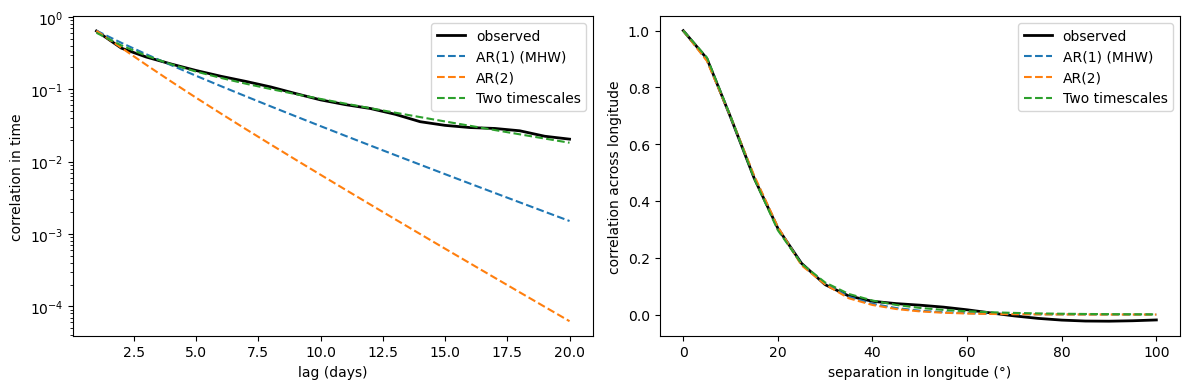

In [5]:
colors = {"AR(1) (MHW)": "tab:blue", "AR(2)": "tab:orange", "Two timescales": "tab:green"}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(time_lags, obs_acf, color="black", linewidth=2, label="observed")
for name, f in fits.items():
    axes[0].plot(time_lags, f["acf"], "--", color=colors[name], label=name)
axes[0].set_xlabel("lag (days)")
axes[0].set_ylabel("correlation in time")
axes[0].set_yscale("log")
axes[0].legend()
axes[1].plot(5 * space_lags, obs_space, color="black", linewidth=2, label="observed")
for name, f in fits.items():
    axes[1].plot(5 * space_lags, f["space"], "--", color=colors[name], label=name)
axes[1].set_xlabel("separation in longitude (°)")
axes[1].set_ylabel("correlation across longitude")
axes[1].legend()
plt.tight_layout()
plt.show()

## Simulation

50 runs, each 44 winters of 90 days (as in MHW); the winter median of B is added back.

In [6]:
N_RUNS, N_DAYS, BURN_IN = 50, 90, 60

def simulate_run(fit, rng):
    """B for one run: (winters, days, longitudes). Sum of the model's components."""
    T = BURN_IN + N_DAYS
    total = np.zeros((len(WINTERS), T, N_LON))
    for (phis, _), sigma in zip(fit["components"], fit["sigmas"]):
        x = np.zeros((len(WINTERS), T, N_LON))
        eps = sigma * rng.standard_normal((len(WINTERS), T, N_LON))
        for t in range(len(phis), T):
            x_star = eps[:, t] + sum(phi * x[:, t - i - 1] for i, phi in enumerate(phis))
            x[:, t] = x_star @ fit["A"].T
        total += x
    return total[:, BURN_IN:] + B_median

## LIB, SB and SBE frequencies (MHW Fig. 2)

LIB: B > 0. SB: LIB at 3 neighbouring longitudes inside the 45° sector centred on that longitude. SBE: SB on that day and the 4 days before it (as MHW count it).

In [7]:
def blocking_flags(B):
    """B: (days, longitudes) for one winter -> LIB, SB, SBE as boolean arrays."""
    lib = B > 0
    run = lib & np.roll(lib, 1, axis=1) & np.roll(lib, -1, axis=1)   # centre of 3 LIB longitudes in a row
    sb = np.zeros_like(lib)
    for k in range(-3, 4):          # run centre within 15°, so all 3 points lie in the sector L-20 ... L+20
        sb |= np.roll(run, k, axis=1)
    fwd = np.zeros(sb.shape, int)   # number of consecutive SB days up to and including each day
    for t in range(len(sb)):
        fwd[t] = sb[t] * (fwd[t - 1] + 1 if t > 0 else 1)
    return lib, sb, fwd >= 5

def frequencies(winters):
    """Fraction of days with LIB, SB, SBE at each longitude."""
    flags = [blocking_flags(B) for B in winters]
    return {name: np.concatenate([f[i] for f in flags]).mean(axis=0) for i, name in enumerate(["LIB", "SB", "SBE"])}

rng = np.random.default_rng(0)
freq_obs = frequencies(B_winters)
freq_runs = {name: [frequencies(simulate_run(f, rng)) for _ in range(N_RUNS)]
             for name, f in fits.items()}

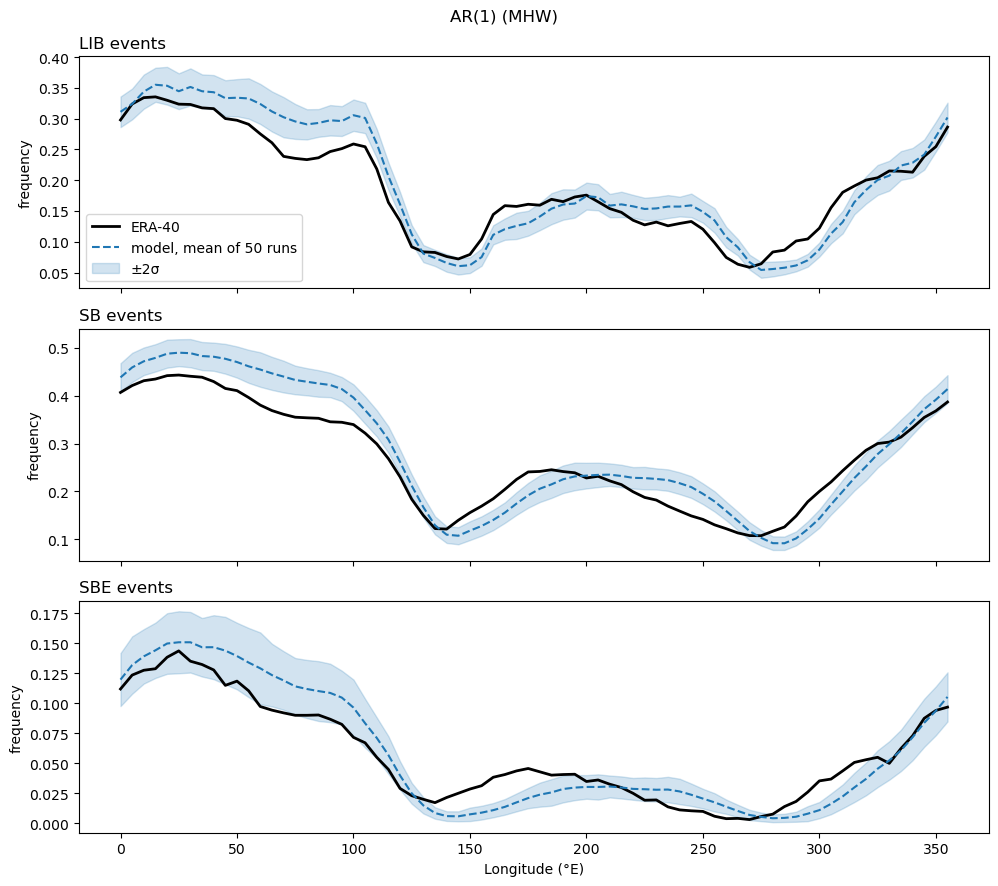

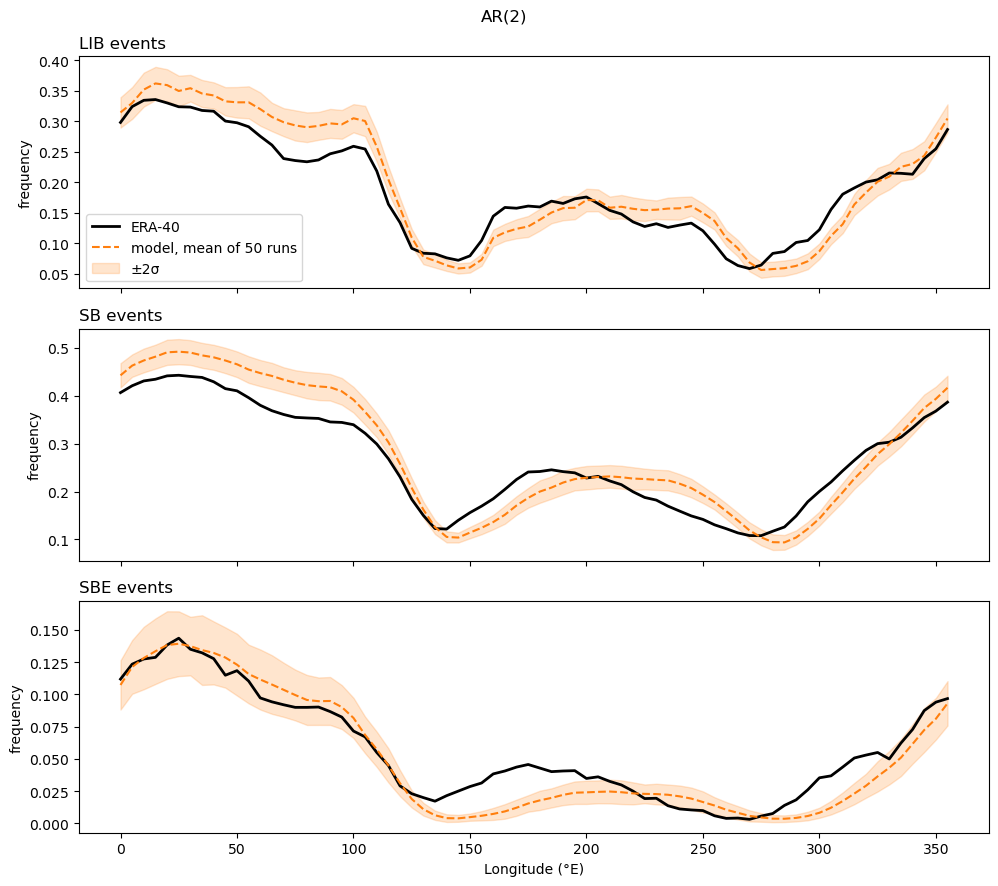

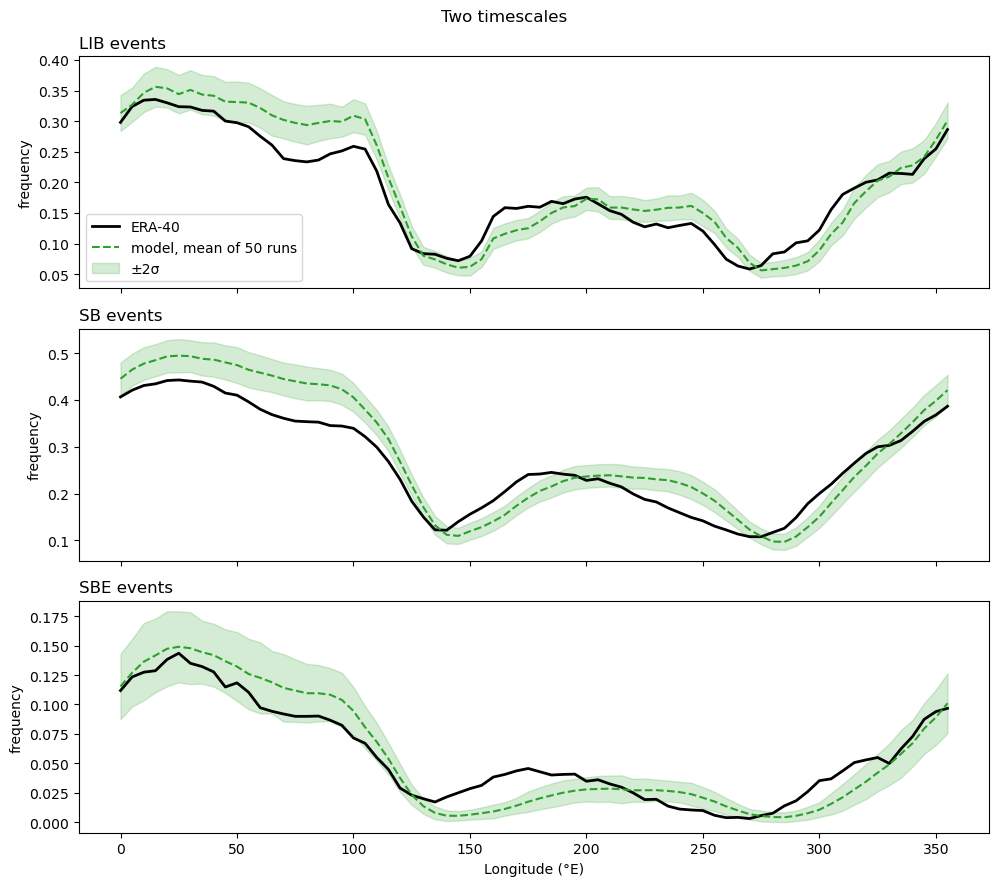

In [8]:
for name, runs in freq_runs.items():
    fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
    fig.suptitle(name)
    for ax, measure in zip(axes, ["LIB", "SB", "SBE"]):
        vals = np.array([r[measure] for r in runs])
        mean, sd = vals.mean(axis=0), vals.std(axis=0)
        ax.plot(lons, freq_obs[measure], color="black", linewidth=2, label="ERA-40")
        ax.plot(lons, mean, "--", color=colors[name], label=f"model, mean of {N_RUNS} runs")
        ax.fill_between(lons, mean - 2 * sd, mean + 2 * sd, color=colors[name], alpha=0.2, label="±2σ")
        ax.set_ylabel("frequency")
        ax.set_title(f"{measure} events", loc="left")
    axes[0].legend()
    axes[-1].set_xlabel("Longitude (°E)")
    plt.tight_layout()
    plt.show()

## Regional red noise

MHW's AR(1) fitted separately in each region of TH08 Fig. 3b (boundaries read off the figure, ±5°): φ, A and noise size come from that region's longitudes only. Simulated on all longitudes, compared only inside the region.

In [9]:
REGIONS = {   # °E, inclusive
    "Atlantic": (300, 350), "Europe": (355, 35), "Asia": (40, 115), "Western Pacific": (120, 155),
    "Central Pacific": (160, 195), "Eastern Pacific": (200, 235), "North America": (240, 295)}

def in_region(start, end):
    return ((lons - start) % 360) <= ((end - start) % 360)

acf_by_lon = np.array([lag_corr(centred, k) for k in time_lags])      # (lags, longitudes)
X_all = np.concatenate(centred)
X_std = X_all / X_all.std(axis=0)

regional = {}
for region, (start, end) in REGIONS.items():
    sel = in_region(start, end)
    acf_r = acf_by_lon[:, sel].mean(axis=1)
    space_r = np.array([(X_std * np.roll(X_std, -m, axis=1))[:, sel].mean() for m in space_lags])
    make, _, bounds, n_lags = model_specs["AR(1) (MHW)"]
    components, A = fit_model(make, [acf_r[0]], bounds, n_lags, acf_target=acf_r, space_target=space_r)
    unit_var = model_stats(components, A)[2][0]
    regional[region] = dict(sel=sel, components=components, A=A,
                            sigmas=[np.sqrt(X_all[:, sel].var(axis=0).mean() / unit_var)])

regional_freq = {region: [frequencies(simulate_run(f, rng)) for _ in range(N_RUNS)] for region, f in regional.items()}

Mean frequency inside each region: observed, regional AR(1), and the whole-hemisphere AR(1) above.

In [10]:
rows = []
for region, f in regional.items():
    sel = f["sel"]
    row = {"region": region, "phi": float(f["components"][0][0][0])}
    for m in ["LIB", "SB", "SBE"]:
        row[f"{m} obs"] = freq_obs[m][sel].mean()
        row[f"{m} regional"] = np.mean([r[m] for r in regional_freq[region]], axis=0)[sel].mean()
        row[f"{m} hemisphere"] = np.mean([r[m] for r in freq_runs["AR(1) (MHW)"]], axis=0)[sel].mean()
    rows.append(row)
print(pd.DataFrame(rows).round(3).to_string(index=False))

         region   phi  LIB obs  LIB regional  LIB hemisphere  SB obs  SB regional  SB hemisphere  SBE obs  SBE regional  SBE hemisphere
       Atlantic 0.766    0.199         0.195           0.187   0.290        0.272          0.273    0.058         0.047           0.048
         Europe 0.839    0.319         0.327           0.337   0.427        0.414          0.467    0.126         0.134           0.137
           Asia 0.733    0.255         0.252           0.302   0.359        0.365          0.423    0.089         0.076           0.112
Western Pacific 0.805    0.090         0.099           0.086   0.159        0.178          0.154    0.024         0.026           0.014
Central Pacific 0.753    0.161         0.176           0.138   0.228        0.261          0.193    0.042         0.040           0.021
Eastern Pacific 0.742    0.145         0.177           0.161   0.204        0.252          0.230    0.026         0.033           0.029
  North America 0.735    0.093         0.108    

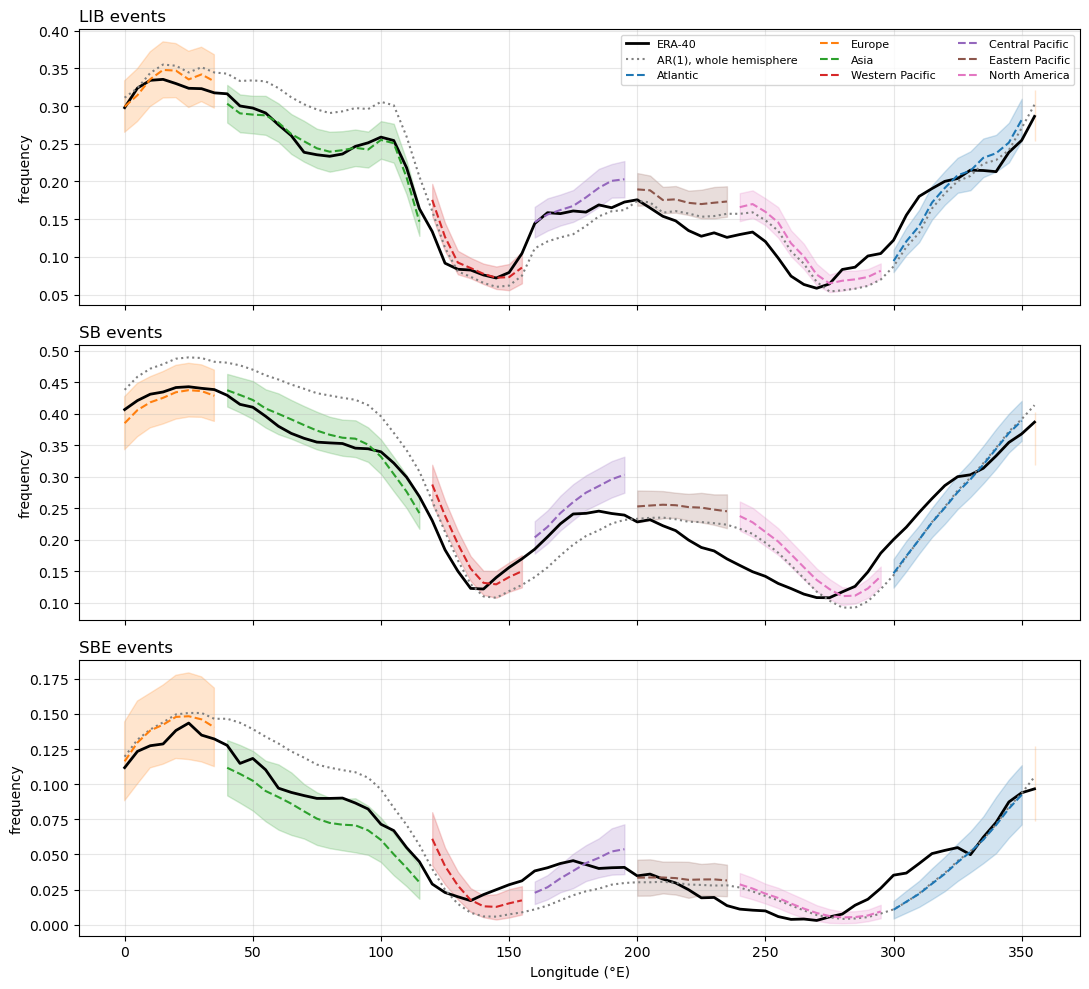

In [11]:
region_colors = dict(zip(REGIONS, plt.cm.tab10.colors))
hemisphere = {m: np.mean([r[m] for r in freq_runs["AR(1) (MHW)"]], axis=0) for m in ["LIB", "SB", "SBE"]}

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, m in zip(axes, ["LIB", "SB", "SBE"]):
    ax.plot(lons, freq_obs[m], color="black", linewidth=2, label="ERA-40")
    ax.plot(lons, hemisphere[m], color="gray", linestyle=":", label="AR(1), whole hemisphere")
    for region, f in regional.items():
        vals = np.array([r[m] for r in regional_freq[region]])
        mean, sd = vals.mean(axis=0), vals.std(axis=0)
        ax.plot(lons, np.where(f["sel"], mean, np.nan), "--", color=region_colors[region], label=region)
        ax.fill_between(lons, mean - 2 * sd, mean + 2 * sd, where=f["sel"], color=region_colors[region], alpha=0.2)
    ax.set_ylabel("frequency")
    ax.set_title(f"{m} events", loc="left")
    ax.grid(alpha=0.3)
axes[0].legend(ncol=3, fontsize=8)
axes[-1].set_xlabel("Longitude (°E)")
plt.tight_layout()
plt.show()

## AR(1) with the winter central latitude

Same AR(1) (MHW) and winters, but B uses the DJF central latitude (`Seasonal B Value Computation.ipynb`) instead of TH08's year-round one.

In [12]:
B_winter_cbl = pd.read_parquet("../results/ERA40_B_index_daily_1957-2002_seasonal-CBL.parquet").rename(columns=int)
Bw_winters = [B_winter_cbl.loc[f"{y-1}-12":f"{y}-02"].to_numpy() for y in WINTERS]
Bw_median = np.median(np.concatenate(Bw_winters), axis=0)
Xw = np.concatenate(Bw_winters) - Bw_median
Xw = Xw - Xw.mean(axis=0)
centred_w = np.split(Xw, np.cumsum([len(b) for b in Bw_winters])[:-1])   # back into winters

acf_w = np.array([lag_corr(centred_w, k).mean() for k in time_lags])
Xw_std = Xw / Xw.std(axis=0)
space_w = np.array([(Xw_std * np.roll(Xw_std, -m, axis=1)).mean() for m in space_lags])

make, _, bounds, n_lags = model_specs["AR(1) (MHW)"]
components, A = fit_model(make, [acf_w[0]], bounds, n_lags, acf_target=acf_w, space_target=space_w)
fit_w = dict(components=components, A=A, sigmas=[np.sqrt(Xw.var(axis=0).mean() / model_stats(components, A)[2][0])])
print(f"lag 1: {acf_w[0]:.3f} (year-round CBL: {obs_acf[0]:.3f}); fitted phi = {components[0][0][0]:.3f}")

freq_obs_w = frequencies(Bw_winters)
# simulate_run adds the year-round-CBL median; swap in the winter-CBL one
freq_runs_w = [frequencies(simulate_run(fit_w, rng) - B_median + Bw_median) for _ in range(N_RUNS)]

lag 1: 0.648 (year-round CBL: 0.637); fitted phi = 0.747


Observed and AR(1) frequencies with the winter central latitude.

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
for ax, m in zip(axes, ["LIB", "SB", "SBE"]):
    vals = np.array([r[m] for r in freq_runs_w])
    mean, sd = vals.mean(axis=0), vals.std(axis=0)
    ax.plot(lons, freq_obs_w[m], color="black", linewidth=2, label="ERA-40")
    ax.plot(lons, mean, "--", color="purple", label=f"AR(1), mean of {N_RUNS} runs")
    ax.fill_between(lons, mean - 2 * sd, mean + 2 * sd, color="purple", alpha=0.2, label="±2σ")
    ax.set_ylabel("frequency")
    ax.set_title(f"{m} events (winter CBL): RMS {np.sqrt(np.mean((mean - freq_obs_w[m]) ** 2)):.3f}", loc="left")
    ax.grid(alpha=0.3)
axes[0].legend()
axes[-1].set_xlabel("Longitude (°E)")
plt.tight_layout()
plt.show()

## Winter + regional AR(1)

The regional AR(1) above (same TH08 regions), fitted on B with the winter central latitude.

In [ ]:
acf_by_lon_w = np.array([lag_corr(centred_w, k) for k in time_lags])   # (lags, longitudes)

regional_w = {}
for region, (start, end) in REGIONS.items():
    sel = in_region(start, end)
    acf_r = acf_by_lon_w[:, sel].mean(axis=1)
    space_r = np.array([(Xw_std * np.roll(Xw_std, -m, axis=1))[:, sel].mean() for m in space_lags])
    components, A = fit_model(make, [acf_r[0]], bounds, n_lags, acf_target=acf_r, space_target=space_r)
    unit_var = model_stats(components, A)[2][0]
    regional_w[region] = dict(sel=sel, components=components, A=A,
                              sigmas=[np.sqrt(Xw[:, sel].var(axis=0).mean() / unit_var)])

# simulate_run adds the year-round-CBL median; swap in the winter-CBL one
regional_freq_w = {region: [frequencies(simulate_run(f, rng) - B_median + Bw_median) for _ in range(N_RUNS)]
                   for region, f in regional_w.items()}

Mean frequency inside each region (winter CBL): observed, regional AR(1), and the whole-hemisphere winter AR(1).

In [ ]:
rows = []
for region, f in regional_w.items():
    sel = f["sel"]
    row = {"region": region, "phi": float(f["components"][0][0][0])}
    for m in ["LIB", "SB", "SBE"]:
        row[f"{m} obs"] = freq_obs_w[m][sel].mean()
        row[f"{m} regional"] = np.mean([r[m] for r in regional_freq_w[region]], axis=0)[sel].mean()
        row[f"{m} hemisphere"] = np.mean([r[m] for r in freq_runs_w], axis=0)[sel].mean()
    rows.append(row)
print(pd.DataFrame(rows).round(3).to_string(index=False))

In [ ]:
hemisphere_w = {m: np.mean([r[m] for r in freq_runs_w], axis=0) for m in ["LIB", "SB", "SBE"]}

fig, axes = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
for ax, m in zip(axes, ["LIB", "SB", "SBE"]):
    ax.plot(lons, freq_obs_w[m], color="black", linewidth=2, label="ERA-40")
    ax.plot(lons, hemisphere_w[m], color="gray", linestyle=":", label="AR(1), whole hemisphere")
    for region, f in regional_w.items():
        vals = np.array([r[m] for r in regional_freq_w[region]])
        mean, sd = vals.mean(axis=0), vals.std(axis=0)
        ax.plot(lons, np.where(f["sel"], mean, np.nan), "--", color=region_colors[region], label=region)
        ax.fill_between(lons, mean - 2 * sd, mean + 2 * sd, where=f["sel"], color=region_colors[region], alpha=0.2)
    ax.set_ylabel("frequency")
    ax.set_title(f"{m} events (winter CBL)", loc="left")
    ax.grid(alpha=0.3)
axes[0].legend(ncol=3, fontsize=8)
axes[-1].set_xlabel("Longitude (°E)")
plt.tight_layout()
plt.show()